# Scaling Law Experiment — Linear Regression

This notebook implements the synthetic linear-regression model of the *Setting* section and
runs three optimizers — **Heavy Ball (HB)**, **Nesterov (NAG)**, and **SGD** — under the
hyper-parameter scaling prescribed by the *Scaling Analysis*. The main deliverable is the
**excess-loss vs. data-size $D$** curve on **log–log axes**, together with fitted slopes,
which should match the theoretical exponent
$$\mathbb{E}[\mathcal{E}_K] \asymp D^{-\,s/(s+1)}.$$

> The notebook is self-contained (only `numpy` + `matplotlib`). It does not need to be run to be
> read, but every cell is executable.

## 1. Setting

$$
\text{Label:}\quad y=\langle\theta^*,x\rangle+\varepsilon,\quad \varepsilon\sim\mathcal{N}(0,\sigma^2)
$$
$$
\text{Data:}\quad x\sim\mathcal{N}(0,H),\qquad H=\mathrm{diag}(\lambda_i),\qquad \lambda_i\asymp i^{-\beta}
$$
$$
\text{Task:}\quad \theta_j^{*\,2}\sim j^{-1-(s-1)\beta}
$$

Because $H$ is diagonal, we work directly in the eigenbasis: each coordinate is independent with
$x_j\sim\mathcal{N}(0,\lambda_j)$. The **population** (test) loss splits into an irreducible part
and the **excess loss**
$$
L(\theta)=\tfrac12\sigma^2+\underbrace{\tfrac12(\theta-\theta^*)^\top H(\theta-\theta^*)}_{\mathcal{E}(\theta)},
\qquad
\mathcal{E}(\theta)=\tfrac12\sum_j \lambda_j\,(\theta_j-\theta_j^*)^2 .
$$
We evaluate $\mathcal{E}$ **analytically** (it is the exact population excess loss), which is both
exact and cheaper than a Monte-Carlo test set.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------- model / task parameters -----------------------------
BETA  = 1.2     # spectrum decay   lambda_j ~ j^{-beta}   (beta > 1)
S     = 1.5     # source/regularity exponent in theta*_j^2 ~ j^{-1-(s-1)beta}
SIGMA = 0.1     # label-noise std
DIM   = 4096    # ambient dimension (truncation of the infinite spectrum)

def build_problem(dim=DIM, beta=BETA, s=S):
    """Return (lam, theta_star) for the diagonal linear-regression problem."""
    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)                       # eigenvalues of H
    var_star = j ** (-(1.0 + (s - 1.0) * beta))   # E[theta*_j^2]
    # deterministic target with the prescribed magnitudes (sign is irrelevant for E)
    theta_star = np.sqrt(var_star)
    return lam, theta_star

LAM, THETA_STAR = build_problem()

def excess_loss(delta, lam=LAM):
    """Exact population excess loss E = 1/2 * sum_j lam_j * delta_j^2, delta = theta - theta*."""
    return 0.5 * np.sum(lam * delta * delta)

print(f'dim={DIM}, lambda range [{LAM[-1]:.2e}, {LAM[0]:.2e}], '
      f'initial excess loss E(0)={excess_loss(-THETA_STAR):.4f}')

dim=4096, lambda range [4.63e-05, 1.00e+00], initial excess loss E(0)=0.6235


## 2. Data generation & stochastic gradient

For a minibatch of size $B$ we draw fresh samples $x_i\sim\mathcal{N}(0,H)$ and
$y_i=\langle\theta^*,x_i\rangle+\varepsilon_i$. Writing $\delta=\theta-\theta^*$, the empirical
gradient is
$$
\nabla\hat L(\theta)=\frac1B\sum_{i=1}^B\big(\langle\delta,x_i\rangle-\varepsilon_i\big)\,x_i
= H\delta+\xi,\qquad \xi\ \text{the gradient noise}.
$$
We run a **single pass** over the data, so the total number of samples consumed is
$B\cdot K \approx D$ — this is exactly the data budget $D$ used in the scaling analysis.
Tracking $\delta$ directly (instead of $\theta$) is convenient because $\theta^*$ is constant and
all update rules are affine in $\delta$.

In [2]:
def sample_batch(B, lam=LAM, theta_star=THETA_STAR, sigma=SIGMA, rng=None):
    """Draw a minibatch. Returns X (B,d) with columns scaled by sqrt(lam) and eps (B,)."""
    rng = rng or np.random.default_rng()
    d = lam.shape[0]
    X = rng.standard_normal((B, d)) * np.sqrt(lam)   # x ~ N(0, H)
    eps = rng.standard_normal(B) * sigma
    return X, eps

def grad_delta(delta, X, eps):
    """Stochastic gradient of the empirical loss expressed in delta = theta - theta*."""
    B = X.shape[0]
    resid = X @ delta - eps          # <theta - theta*, x> - eps  = pred - y
    return (X.T @ resid) / B

## 3. Algorithms

All three share the affine recursion in $\delta_t=\theta_t-\theta^*$ (initialised at $\theta_0=0$,
i.e. $\delta_0=-\theta^*$).

**Heavy Ball (HB).**
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t)+\rho\,(\theta_t-\theta_{t-1}).$$

**Nesterov (NAG).** Gradient evaluated at the extrapolated point:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L\big(\theta_t+\rho(\theta_t-\theta_{t-1})\big)+\rho\,(\theta_t-\theta_{t-1}).$$

**SGD.** The special case $\rho=0$:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t).$$

Each step consumes one fresh minibatch of size $B$; we run $K$ steps and return the final excess loss.

In [3]:
def run_optimizer(algo, B, K, eta, rho, rng=None):
    """Run one of {'hb','nag','sgd'} for K steps of batch size B. Returns (final_E, curve)."""
    rng = rng or np.random.default_rng()
    delta = -THETA_STAR.copy()      # theta_0 = 0  =>  delta_0 = -theta*
    delta_prev = delta.copy()       # theta_{-1} = theta_0 (zero initial velocity)
    curve = np.empty(K + 1)
    curve[0] = excess_loss(delta)
    for t in range(K):
        X, eps = sample_batch(B, rng=rng)
        momentum = delta - delta_prev       # theta_t - theta_{t-1}
        if algo == 'nag':
            g = grad_delta(delta + rho * momentum, X, eps)
        else:                                # 'hb' or 'sgd'
            g = grad_delta(delta, X, eps)
        delta_new = delta - eta * g + rho * momentum
        delta_prev, delta = delta, delta_new
        curve[t + 1] = excess_loss(delta)
    return curve[-1], curve

## 4. Hyper-parameter scaling with $D$

From the interior optimal family $a+c-b=\tfrac{s}{s+1}$ (with $a+b<1,\ c\ge0$), maximising the
batch exponent $a$ gives, for **HB / Nesterov**,
$$
a_{\max}=\frac{2s+1}{2s+2},\qquad b_*=\frac{1}{2s+2},\qquad c_*=0,
$$
i.e.
$$
B(D)\asymp D^{\frac{2s+1}{2s+2}},\quad
K(D)\asymp D^{\frac{1}{2s+2}},\quad
1-\rho(D)\asymp D^{-\frac{1}{2s+2}},\quad
\eta(D)\asymp 1.
$$

For the **SGD** baseline, balancing $(\eta K)^{-s}+\eta/B$ under $BK\asymp D$ gives $a+c=\tfrac{s}{s+1}$;
the largest-batch choice is
$$
B(D)\asymp D^{\frac{s}{s+1}},\quad K(D)\asymp D^{\frac{1}{s+1}},\quad \eta(D)\asymp1.
$$

The constants $C_B,C_K,C_\rho,C_\eta$ are fixed once (a pilot choice below) and held constant across all $D$.

In [4]:
# ----------------------------- fixed constants (pilot) -----------------------------
C_B, C_K, C_RHO, C_ETA = 0.1, 10, 1.0, 0.5

def hb_nag_schedule(D, s=S):
    """B, K, eta, rho for HB / Nesterov at data budget D."""
    aB = (2 * s + 1) / (2 * s + 2)
    aK = 1.0 / (2 * s + 2)
    B = max(1, int(C_B * D ** aB))
    K = max(1, int(C_K * D ** aK))
    one_minus_rho = min(1.0, C_RHO * D ** (-1.0 / (2 * s + 2)))
    rho = 1.0 - one_minus_rho
    eta = C_ETA
    return B, K, eta, rho

def sgd_schedule(D, s=S):
    """B, K, eta, rho(=0) for SGD at data budget D."""
    aB = (2 * s + 1) / (2 * s + 2)
    aK = 1.0 / (2 * s + 2)
    B = max(1, int(C_B * D ** aB))
    K = max(1, int(C_K * D ** aK))
    eta = C_ETA
    return B, K, eta, 0.0

# quick sanity print of the schedules
for D in [2**10, 2**14]:
    print(f'D=2^{int(np.log2(D)):d}:  HB/NAG {hb_nag_schedule(D)},  SGD {sgd_schedule(D)}')

D=2^10:  HB/NAG (25, 40, 0.5, 0.75),  SGD (25, 40, 0.5, 0.0)
D=2^14:  HB/NAG (235, 69, 0.5, 0.8564127056253706),  SGD (235, 69, 0.5, 0.0)


## 5. Run the scaling sweep

We sweep a geometric sequence of data sizes and average the final excess loss over several seeds.
The default range is kept modest so the notebook runs in reasonable time; push `D_EXPONENTS` up to
`18` (as in the plan) and increase `DIM` for a cleaner asymptotic slope.

> **Cost note.** For HB/NAG the batch grows like $D^{(2s+1)/(2s+2)}$, so the per-step matrix is
> $B\times\text{DIM}$. Memory/compute scale accordingly at large $D$.

In [5]:
D_EXPONENTS = list(range(10, 16))          # D = 2^10 ... 2^15  (raise to 18 for the full plan)
D_LIST = [2 ** e for e in D_EXPONENTS]
N_SEEDS = 3

ALGOS = {
    'HB'      : ('hb',  hb_nag_schedule),
    'Nesterov': ('nag', hb_nag_schedule),
    'SGD'     : ('sgd', sgd_schedule),
}

results = {name: {'mean': [], 'std': []} for name in ALGOS}

for name, (algo, sched) in ALGOS.items():
    for D in D_LIST:
        B, K, eta, rho = sched(D)
        vals = []
        for seed in range(N_SEEDS):
            rng = np.random.default_rng(1000 * seed + D)
            final_E, _ = run_optimizer(algo, B, K, eta, rho, rng=rng)
            vals.append(final_E)
        vals = np.array(vals)
        results[name]['mean'].append(vals.mean())
        results[name]['std'].append(vals.std())
        print(f'{name:9s} D=2^{int(np.log2(D)):<2d}  B={B:<6d} K={K:<4d} '
              f'rho={rho:.3f}  E_K={vals.mean():.3e} +/- {vals.std():.1e}')
    print()

HB        D=2^10  B=25     K=40   rho=0.750  E_K=1.755e-03 +/- 1.5e-04
HB        D=2^11  B=44     K=45   rho=0.782  E_K=1.271e-03 +/- 3.7e-05
HB        D=2^12  B=77     K=52   rho=0.811  E_K=5.869e-04 +/- 2.6e-05
HB        D=2^13  B=135    K=60   rho=0.835  E_K=4.085e-04 +/- 6.2e-05
HB        D=2^14  B=235    K=69   rho=0.856  E_K=3.081e-04 +/- 2.0e-05
HB        D=2^15  B=409    K=80   rho=0.875  E_K=1.873e-04 +/- 3.7e-05

Nesterov  D=2^10  B=25     K=40   rho=0.750  E_K=1.055e-03 +/- 1.6e-04
Nesterov  D=2^11  B=44     K=45   rho=0.782  E_K=8.093e-04 +/- 5.8e-05
Nesterov  D=2^12  B=77     K=52   rho=0.811  E_K=4.139e-04 +/- 4.3e-05
Nesterov  D=2^13  B=135    K=60   rho=0.835  E_K=2.497e-04 +/- 3.8e-05
Nesterov  D=2^14  B=235    K=69   rho=0.856  E_K=1.863e-04 +/- 8.1e-06
Nesterov  D=2^15  B=409    K=80   rho=0.875  E_K=1.053e-04 +/- 1.9e-05

SGD       D=2^10  B=25     K=40   rho=0.000  E_K=1.641e-03 +/- 9.0e-05
SGD       D=2^11  B=44     K=45   rho=0.000  E_K=1.545e-03 +/- 6.4e-05
SGD 

## 6. Log–log plot: excess loss vs. $D$ + fitted slopes

We fit $\log\mathcal{E}_K$ against $\log D$ for each algorithm and compare the measured slope with
the theoretical prediction $-\,s/(s+1)$. A reference power-law line is drawn for orientation.

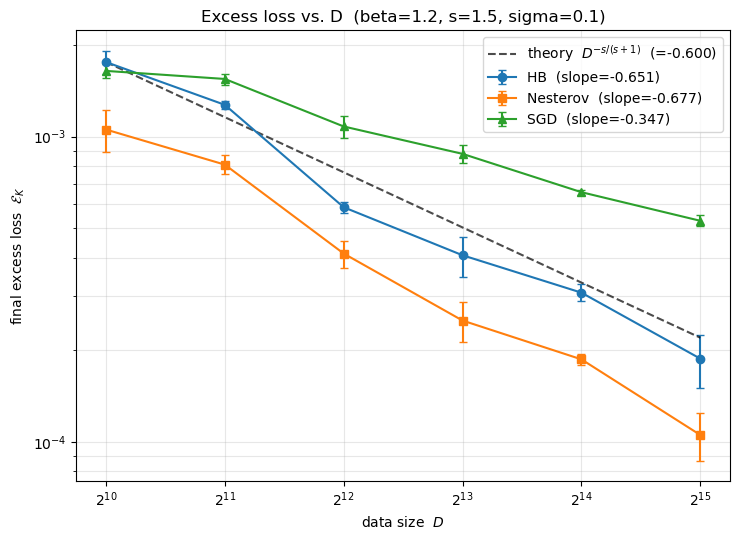

theoretical exponent  -s/(s+1) = -0.6000
  measured slope HB       : -0.6513
  measured slope Nesterov : -0.6773
  measured slope SGD      : -0.3472


In [6]:
theory_exp = S / (S + 1.0)          # predicted decay exponent  s/(s+1)
logD = np.log(np.array(D_LIST, dtype=float))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
markers = {'HB': 'o', 'Nesterov': 's', 'SGD': '^'}
slopes = {}

for name in ALGOS:
    mean = np.array(results[name]['mean'])
    std  = np.array(results[name]['std'])
    slope, intercept = np.polyfit(logD, np.log(mean), 1)
    slopes[name] = slope
    ax.errorbar(D_LIST, mean, yerr=std, marker=markers[name], capsize=3,
                linestyle='-', label=f'{name}  (slope={slope:.3f})')

# reference line  ~ D^{-s/(s+1)} anchored at the first point of HB
anchor = np.array(results['HB']['mean'])[0]
ref = anchor * (np.array(D_LIST, float) / D_LIST[0]) ** (-theory_exp)
ax.plot(D_LIST, ref, 'k--', alpha=0.7,
        label=f'theory  $D^{{-s/(s+1)}}$  (={-theory_exp:.3f})')

ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xlabel('data size  $D$')
ax.set_ylabel(r'final excess loss  $\mathcal{E}_K$')
ax.set_title(f'Excess loss vs. D  (beta={BETA}, s={S}, sigma={SIGMA})')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f'theoretical exponent  -s/(s+1) = {-theory_exp:.4f}')
for name, sl in slopes.items():
    print(f'  measured slope {name:9s}: {sl:.4f}')

## 7. Training curves for representative $D$

Excess loss vs. optimization step for a few $D$ values, to visualise the transient + polynomial phases.

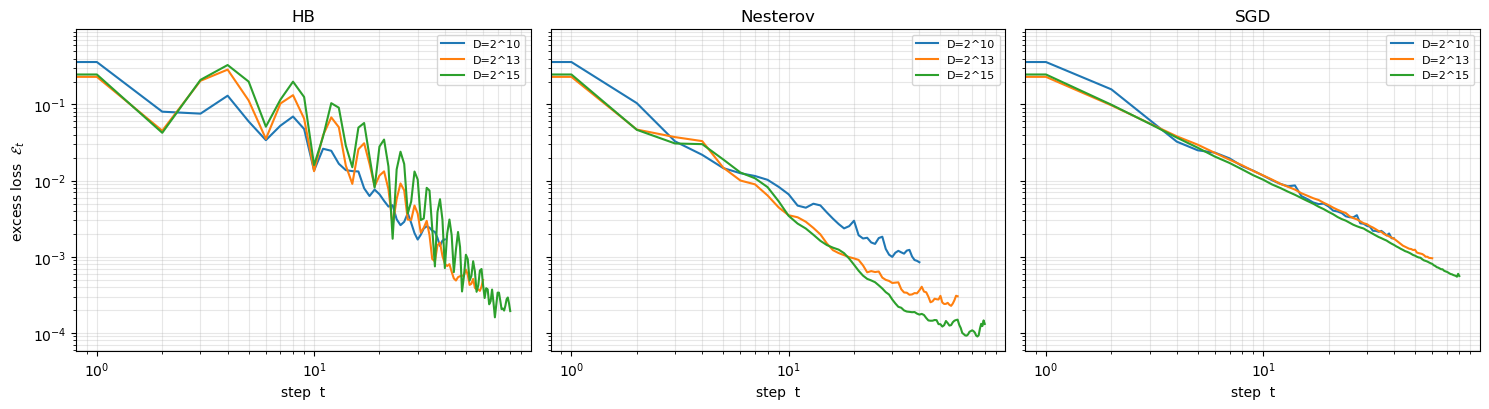

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
rep_D = [2 ** e for e in (D_EXPONENTS[0], D_EXPONENTS[len(D_EXPONENTS)//2], D_EXPONENTS[-1])]

for ax, (name, (algo, sched)) in zip(axes, ALGOS.items()):
    for D in rep_D:
        B, K, eta, rho = sched(D)
        rng = np.random.default_rng(D)
        _, curve = run_optimizer(algo, B, K, eta, rho, rng=rng)
        ax.plot(np.arange(len(curve)), curve, label=f'D=2^{int(np.log2(D))}')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(name)
    ax.set_xlabel('step  t')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel(r'excess loss  $\mathcal{E}_t$')
plt.tight_layout()
plt.show()

## 8. Expected outcome

The linear theory predicts the **same** polynomial exponent for HB and Nesterov,
$$\mathbb{E}[\mathcal{E}_K]\asymp D^{-s/(s+1)},$$
so their fitted slopes should coincide (up to constants — Nesterov may have a smaller prefactor).
SGD attains the same asymptotic exponent but with a **smaller feasible batch exponent**
($a_{\max}^{\mathrm{SGD}}=\tfrac{s}{s+1}$ vs. $a_{\max}^{\mathrm{HB/NAG}}=\tfrac{2s+1}{2s+2}$),
so the momentum methods' advantage shows up as better constants / finite-$D$ behaviour and larger
admissible batch size, rather than a strictly steeper power law. Roughly,
$$\text{Nesterov}\ \lesssim\ \text{HB}\ \lesssim\ \text{SGD}\quad\text{in final loss at fixed }D.$$